In [62]:
import pandas as pd
import numpy as np
df=pd.read_csv('D:\college ml project\EnergySense\data\processed/household_power_cleaned.csv')
df.head()

,timestamp,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,2006-12-16 17:24:00,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,2006-12-16 17:25:00,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,2006-12-16 17:26:00,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,2006-12-16 17:27:00,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,2006-12-16 17:28:00,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


In [63]:
df.dtypes

timestamp                 object
Date                      object
Time                      object
Global_active_power      float64
Global_reactive_power    float64
Voltage                  float64
Global_intensity         float64
Sub_metering_1           float64
Sub_metering_2           float64
Sub_metering_3           float64
dtype: object

In [64]:
df.columns

Index(['timestamp', 'Date', 'Time', 'Global_active_power',
       'Global_reactive_power', 'Voltage', 'Global_intensity',
       'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3'],
      dtype='object')

In [65]:
df.isnull().sum()

timestamp                    0
Date                         0
Time                         0
Global_active_power      25903
Global_reactive_power    25903
Voltage                  25903
Global_intensity         25903
Sub_metering_1           25903
Sub_metering_2           25903
Sub_metering_3           25903
dtype: int64

In [66]:
df.shape

(2075259, 10)

In [67]:
df['timestamp'].dtypes

dtype('O')

In [68]:
df['timestamp'].isnull().sum()

np.int64(0)

In [69]:
df['timestamp']=pd.to_datetime(df['timestamp'],format='%Y-%m-%d %H:%M:%S')

In [70]:
df.set_index('timestamp',inplace=True)
df.index

DatetimeIndex(['2006-12-16 17:24:00', '2006-12-16 17:25:00',
               '2006-12-16 17:26:00', '2006-12-16 17:27:00',
               '2006-12-16 17:28:00', '2006-12-16 17:29:00',
               '2006-12-16 17:30:00', '2006-12-16 17:31:00',
               '2006-12-16 17:32:00', '2006-12-16 17:33:00',
               ...
               '2010-11-26 20:53:00', '2010-11-26 20:54:00',
               '2010-11-26 20:55:00', '2010-11-26 20:56:00',
               '2010-11-26 20:57:00', '2010-11-26 20:58:00',
               '2010-11-26 20:59:00', '2010-11-26 21:00:00',
               '2010-11-26 21:01:00', '2010-11-26 21:02:00'],
              dtype='datetime64[ns]', name='timestamp', length=2075259, freq=None)

In [71]:
df.index.is_monotonic_increasing

True

In [72]:
df['Global_active_power'].describe()

count    2.049356e+06
mean     1.091645e+00
std      1.057324e+00
min      7.600000e-02
25%      3.080000e-01
50%      6.020000e-01
75%      1.528000e+00
max      1.112200e+01
Name: Global_active_power, dtype: float64

In [73]:
pip install seaborn

<Axes: xlabel='Global_active_power', ylabel='Count'>

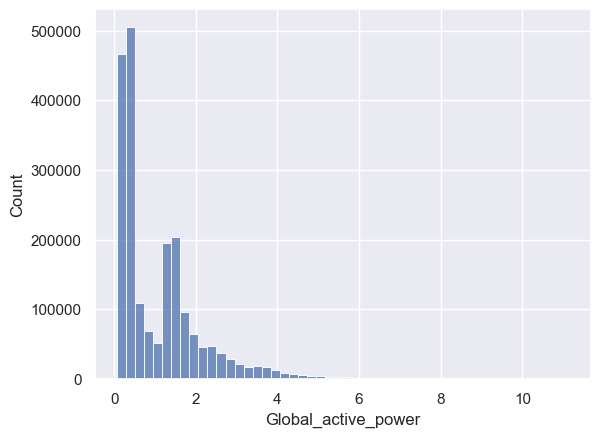

In [74]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.set_theme()
sns.histplot(
    data=df,
    x='Global_active_power',
    bins=50
)

<Axes: ylabel='Global_active_power'>

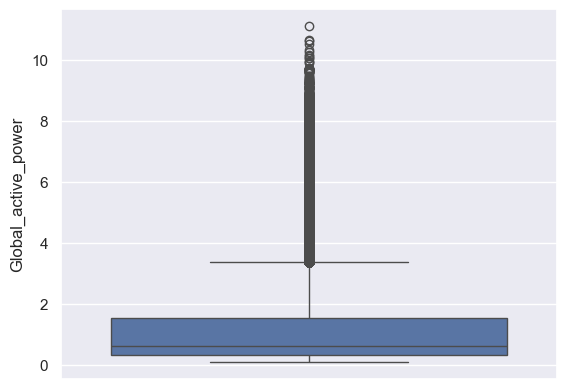

In [75]:
sns.boxplot(
    data=df,
    y='Global_active_power'
)


In [76]:
hourly_power=df['Global_active_power'].resample('h').mean()

In [77]:
hourly_tottal=df['Global_active_power'].resample('h').sum()

In [78]:
hourly_count = df['Global_active_power'].resample('h').count()
print(hourly_count.head())
print(hourly_count.tail())
print(hourly_count.describe())

timestamp
2006-12-16 17:00:00    36
2006-12-16 18:00:00    60
2006-12-16 19:00:00    60
2006-12-16 20:00:00    60
2006-12-16 21:00:00    60
Freq: h, Name: Global_active_power, dtype: int64
timestamp
2010-11-26 17:00:00    60
2010-11-26 18:00:00    60
2010-11-26 19:00:00    60
2010-11-26 20:00:00    60
2010-11-26 21:00:00     3
Freq: h, Name: Global_active_power, dtype: int64
count    34589.000000
mean        59.248779
std          6.636200
min          0.000000
25%         60.000000
50%         60.000000
75%         60.000000
max         60.000000
Name: Global_active_power, dtype: float64


In [79]:
count_hour=hourly_count.eq(60)
count_hour.sum()

np.int64(34139)

In [80]:
count_zero=hourly_count.eq(0)
count_zero.sum()

np.int64(421)

In [81]:
count_less=hourly_count<60
count_less.sum()

np.int64(450)

In [82]:
df

,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
timestamp,,,,,,,,,
2006-12-16 17:24:00,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
2006-12-16 17:25:00,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2006-12-16 17:26:00,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
2006-12-16 17:27:00,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
2006-12-16 17:28:00,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0
...,...,...,...,...,...,...,...,...,...
2010-11-26 20:58:00,26/11/2010,20:58:00,0.946,0.000,240.43,4.0,0.0,0.0,0.0
2010-11-26 20:59:00,26/11/2010,20:59:00,0.944,0.000,240.00,4.0,0.0,0.0,0.0
2010-11-26 21:00:00,26/11/2010,21:00:00,0.938,0.000,239.82,3.8,0.0,0.0,0.0


In [85]:
hour_extract=df.index.hour

In [88]:

maphh=pd.DataFrame(df['Global_active_power'].groupby(hour_extract).mean())
maphh

,Global_active_power
timestamp,
0,0.659434
1,0.539325
2,0.480618
3,0.444866
4,0.443847
5,0.453674
6,0.791631
7,1.502264
8,1.461049


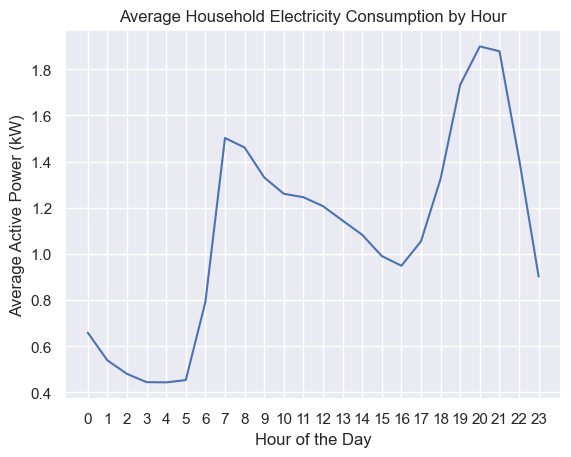

In [102]:

sns.lineplot(
    data=maphh,
    x='timestamp',
    y='Global_active_power',
)
plt.title('Average Household Electricity Consumption by Hour')
plt.xlabel('Hour of the Day')
plt.ylabel('Average Active Power (kW)')
plt.xticks(range(24))
plt.grid(True)
plt.show()


In [112]:
weekday_extract = pd.Series(df.index.dayofweek, index=df.index)
weekday_extract

timestamp
2006-12-16 17:24:00    5
2006-12-16 17:25:00    5
2006-12-16 17:26:00    5
2006-12-16 17:27:00    5
2006-12-16 17:28:00    5
                      ..
2010-11-26 20:58:00    4
2010-11-26 20:59:00    4
2010-11-26 21:00:00    4
2010-11-26 21:01:00    4
2010-11-26 21:02:00    4
Name: timestamp, Length: 2075259, dtype: int32

In [118]:
print(weekday_extract.eq(6).sum())
print(weekday_extract.eq(5).sum())
print(weekday_extract.eq(4).sum())
print(weekday_extract.eq(3).sum())
print(weekday_extract.eq(2).sum())
print(weekday_extract.eq(1).sum())
print(weekday_extract.eq(0).sum())

296640
295596
296463
296640
296640
296640
296640


In [120]:
weekday_profile=pd.DataFrame(df['Global_active_power'].groupby(weekday_extract).mean())
weekday_profile

,Global_active_power
timestamp,
0,0.999560
1,1.069802
2,1.082656
3,0.981840
4,1.043394
5,1.248391
6,1.220220


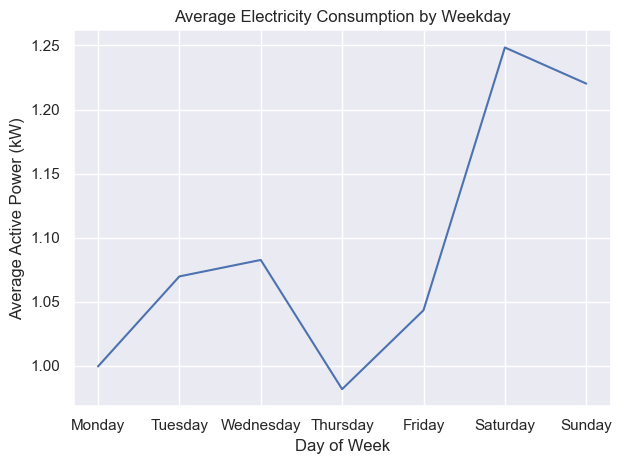

In [127]:
sns.lineplot(
    data=weekday_profile,
    x='timestamp',
    y='Global_active_power'
)
plt.title('Average Electricity Consumption by Weekday')
plt.xlabel('Day of Week')
plt.ylabel('Average Active Power (kW)')

plt.xticks(
    range(7),
    ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday'],
    
)

plt.grid(True)
plt.tight_layout()
plt.show()

In [134]:
monthly_extract = pd.Series(df.index.month, index=df.index)
monthly_extract

timestamp
2006-12-16 17:24:00    12
2006-12-16 17:25:00    12
2006-12-16 17:26:00    12
2006-12-16 17:27:00    12
2006-12-16 17:28:00    12
                       ..
2010-11-26 20:58:00    11
2010-11-26 20:59:00    11
2010-11-26 21:00:00    11
2010-11-26 21:01:00    11
2010-11-26 21:02:00    11
Name: timestamp, Length: 2075259, dtype: int32

In [136]:
monthly_profile=pd.DataFrame(df['Global_active_power'].groupby(monthly_extract).mean())
monthly_profile

,Global_active_power
timestamp,
1,1.462296
2,1.300500
3,1.231374
4,1.047136
5,1.029572
6,0.909157
7,0.700388
8,0.572818
9,0.975709


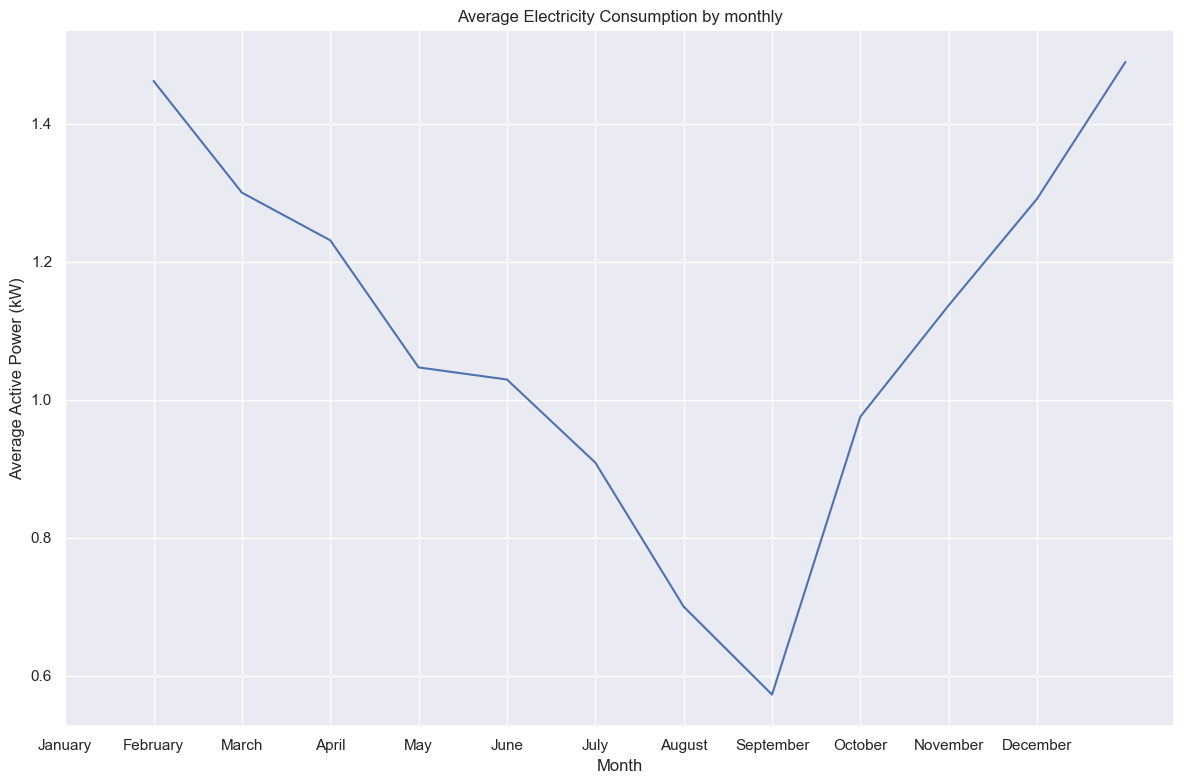

In [138]:
fig, ax = plt.subplots(figsize=(12, 8))
sns.lineplot(
    data=monthly_profile,
    x='timestamp',
    y='Global_active_power'
)
plt.title('Average Electricity Consumption by monthly')
plt.xlabel('Month')
plt.ylabel('Average Active Power (kW)')

plt.xticks(
    range(12),
    [ 'January', 'February', 'March', 'April', 'May', 'June', 'July', 'August', 'September', 'October', 'November', 'December'],
    
)

plt.grid(True)
plt.tight_layout()
plt.show()

In [139]:
yearly_extract = pd.Series(df.index.year, index=df.index)
yearly_extract

timestamp
2006-12-16 17:24:00    2006
2006-12-16 17:25:00    2006
2006-12-16 17:26:00    2006
2006-12-16 17:27:00    2006
2006-12-16 17:28:00    2006
                       ... 
2010-11-26 20:58:00    2010
2010-11-26 20:59:00    2010
2010-11-26 21:00:00    2010
2010-11-26 21:01:00    2010
2010-11-26 21:02:00    2010
Name: timestamp, Length: 2075259, dtype: int32

In [145]:
yearly_profile=pd.DataFrame(df['Global_active_power'].groupby(yearly_extract).mean())
yearly_profile

,Global_active_power
timestamp,
2006,1.901564
2007,1.117042
2008,1.072116
2009,1.078667
2010,1.061021


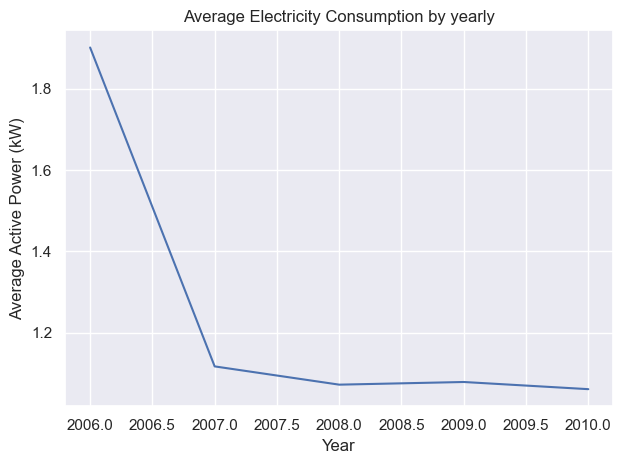

In [147]:

sns.lineplot(
    data=yearly_profile,
    x='timestamp',
    y='Global_active_power'
)
plt.title('Average Electricity Consumption by yearly')
plt.xlabel('Year')
plt.ylabel('Average Active Power (kW)')



plt.grid(True)
plt.tight_layout()
plt.show()

In [148]:
corr_matrix = df.select_dtypes(include='number').corr()
corr_matrix

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
Global_active_power,1.000000,0.247036,-0.399767,0.998889,0.484409,0.434578,0.638552
Global_reactive_power,0.247036,1.000000,-0.112253,0.266138,0.123123,0.139246,0.089615
Voltage,-0.399767,-0.112253,1.000000,-0.411369,-0.195970,-0.167409,-0.268178
Global_intensity,0.998889,0.266138,-0.411369,1.000000,0.489305,0.440356,0.626539
Sub_metering_1,0.484409,0.123123,-0.195970,0.489305,1.000000,0.054735,0.102578
Sub_metering_2,0.434578,0.139246,-0.167409,0.440356,0.054735,1.000000,0.080874
Sub_metering_3,0.638552,0.089615,-0.268178,0.626539,0.102578,0.080874,1.000000


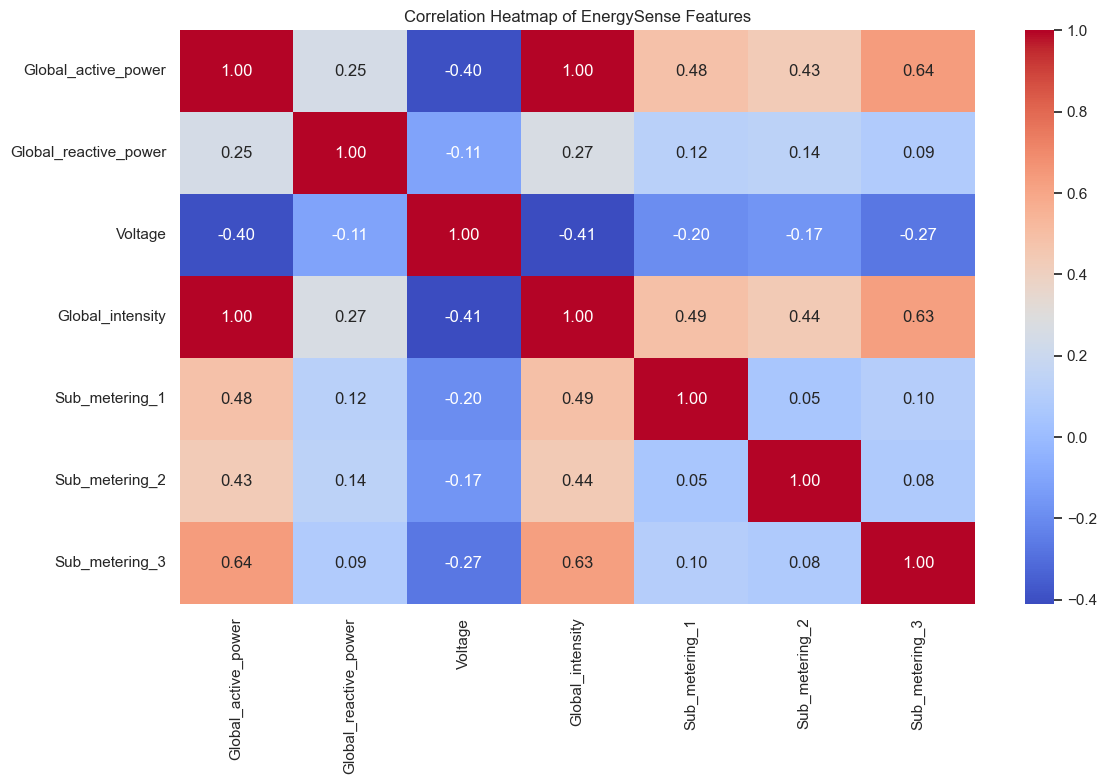

In [151]:

fig, ax = plt.subplots(figsize=(12, 8))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)
plt.title('Correlation Heatmap of EnergySense Features')
plt.tight_layout()
plt.show()